## Compute velocity graph from MultiVelo output
Get the graph and stream embedding and further analyse which genes are weighted most/have the best fit.

In [1]:
import scanpy as sc
import numpy as np 
import matplotlib.pyplot as plt
import multivelo as mv
import pandas as pd
import scvelo as scv
from pathlib import Path
from scipy.spatial.distance import cdist, euclidean
from scipy.optimize import linear_sum_assignment
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from matplotlib.collections import LineCollection
from sklearn.neighbors import NearestNeighbors

python_data_dir = r"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_testing\data"

scv.settings.verbosity = 3
scv.settings.presenter_view = True
scv.set_figure_params('scvelo')
scv.settings.figdir = rf"{python_data_dir}\multivelo_comparison"
scv.settings.plot_prefix = ""
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 200)
np.set_printoptions(suppress=True)

In [2]:
adata_result = sc.read_h5ad(rf"{python_data_dir}\multivelo_results_v3.h5ad")

In [6]:
adata_result

AnnData object with n_obs × n_vars = 5241 × 310
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Sample', 'TSSEnrichment', 'ReadsInTSS', 'ReadsInPromoter', 'ReadsInBlacklist', 'PromoterRatio', 'PassQC', 'NucleosomeRatio', 'nMultiFrags', 'nMonoFrags', 'nFrags', 'nDiFrags', 'BlacklistRatio', 'percent.mt', 'nCount_SCT', 'nFeature_SCT', 'S.Score', 'G2M.Score', 'Phase', 'SCT_snn_res.0.8', 'seurat_clusters', 'doublets_normal_cluster_based', 'doublets_random', 'doublets_RNA_consensus', 'nCount_SCT_no_regression', 'nFeature_SCT_no_regression', 'tricyclePosition', 'Phase_tricycle', 'tricycle_fine', 'cell_cycle_atac_classification', 'PromoterPercent', 'immunophenotype_predicted', 'predicted.id', 'prediction.score.LT', 'prediction.score.ST', 'prediction.score.MPP', 'prediction.score.LS_K', 'prediction.score.max', 'Identity_for_diff_testing', 'RF_prediction', 'angle_degree', 'immunophenotype_predicted_cleaned', 'HSC.promoters', 'LMPP.promoters', 'myeloid.promoters', 'MEP.promoters', 'HSC.TSS'

In [7]:
adata_result.uns["velo_s_params"]

{'fig_size': array([8, 6], dtype=int64),
 'fit_decoupling': True,
 'init_mode': 'invert',
 'k': 1,
 'max_iter': 20,
 'mode': 'dynamical',
 'n_neighbors': 30,
 'n_pcs': 30,
 'outlier': 99.8,
 'point_size': 7,
 't': 500,
 'thresh_multiplier': 1.0,
 'weight_c': 0.6}

In [10]:
adata_result.layers["velo_comb"] = adata_result.layers["velo_s"] + adata_result.layers["velo_u"] 
adata_result.uns["velo_comb_params"] = adata_result.uns["velo_s_params"]
adata_result.var["velo_comb_genes"] = adata_result.var["velo_s_genes"]

computing velocity graph (using 1/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:16) --> added 
    'velo_comb_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing terminal states
    identified 0 region of root cells and 1 region of end points .
    finished (0:00:01) --> added
    'root_cells', root cells of Markov diffusion process (adata.obs)
    'end_points', end points of Markov diffusion process (adata.obs)
computing latent time using root_cells as prior
    finished (0:00:02) --> added 
    'latent_time', shared time (adata.obs)
computing velocity embedding
    finished (0:00:03) --> added
    'velo_comb_norm_umap', embedded velocity vectors (adata.obsm)


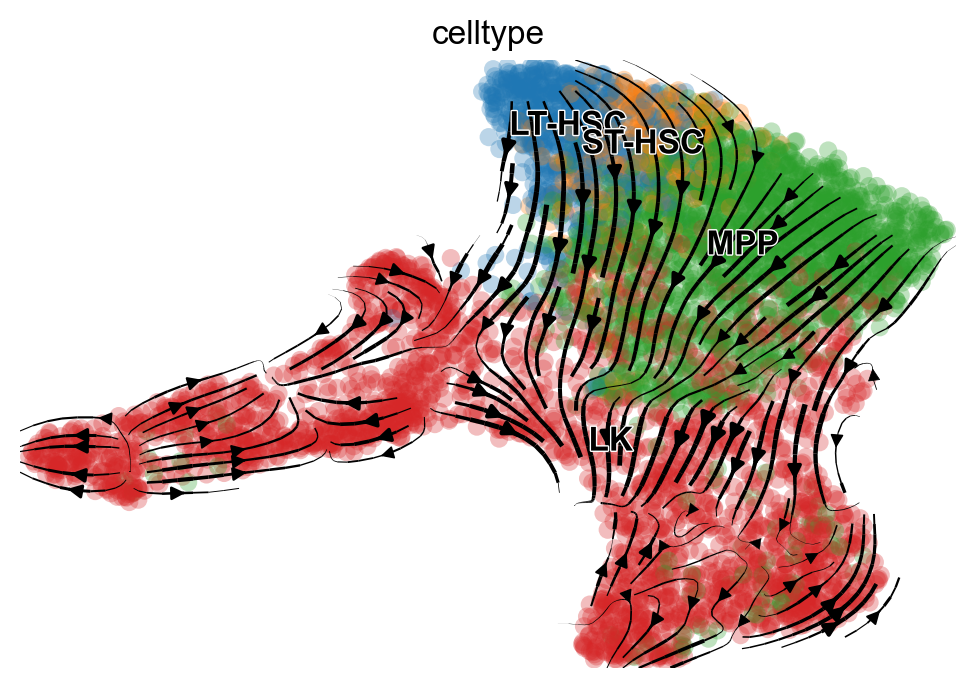

In [11]:
mv.velocity_graph(adata_result, vkey="velo_comb")
mv.latent_time(adata_result, vkey="velo_comb")
mv.velocity_embedding_stream(adata_result, basis='umap', color='celltype', vkey="velo_comb")
# multivelo_plot_path = f"{output_path}multivelo_velocity_stream_umap.png"
# plt.savefig(multivelo_plot_path, dpi=150)

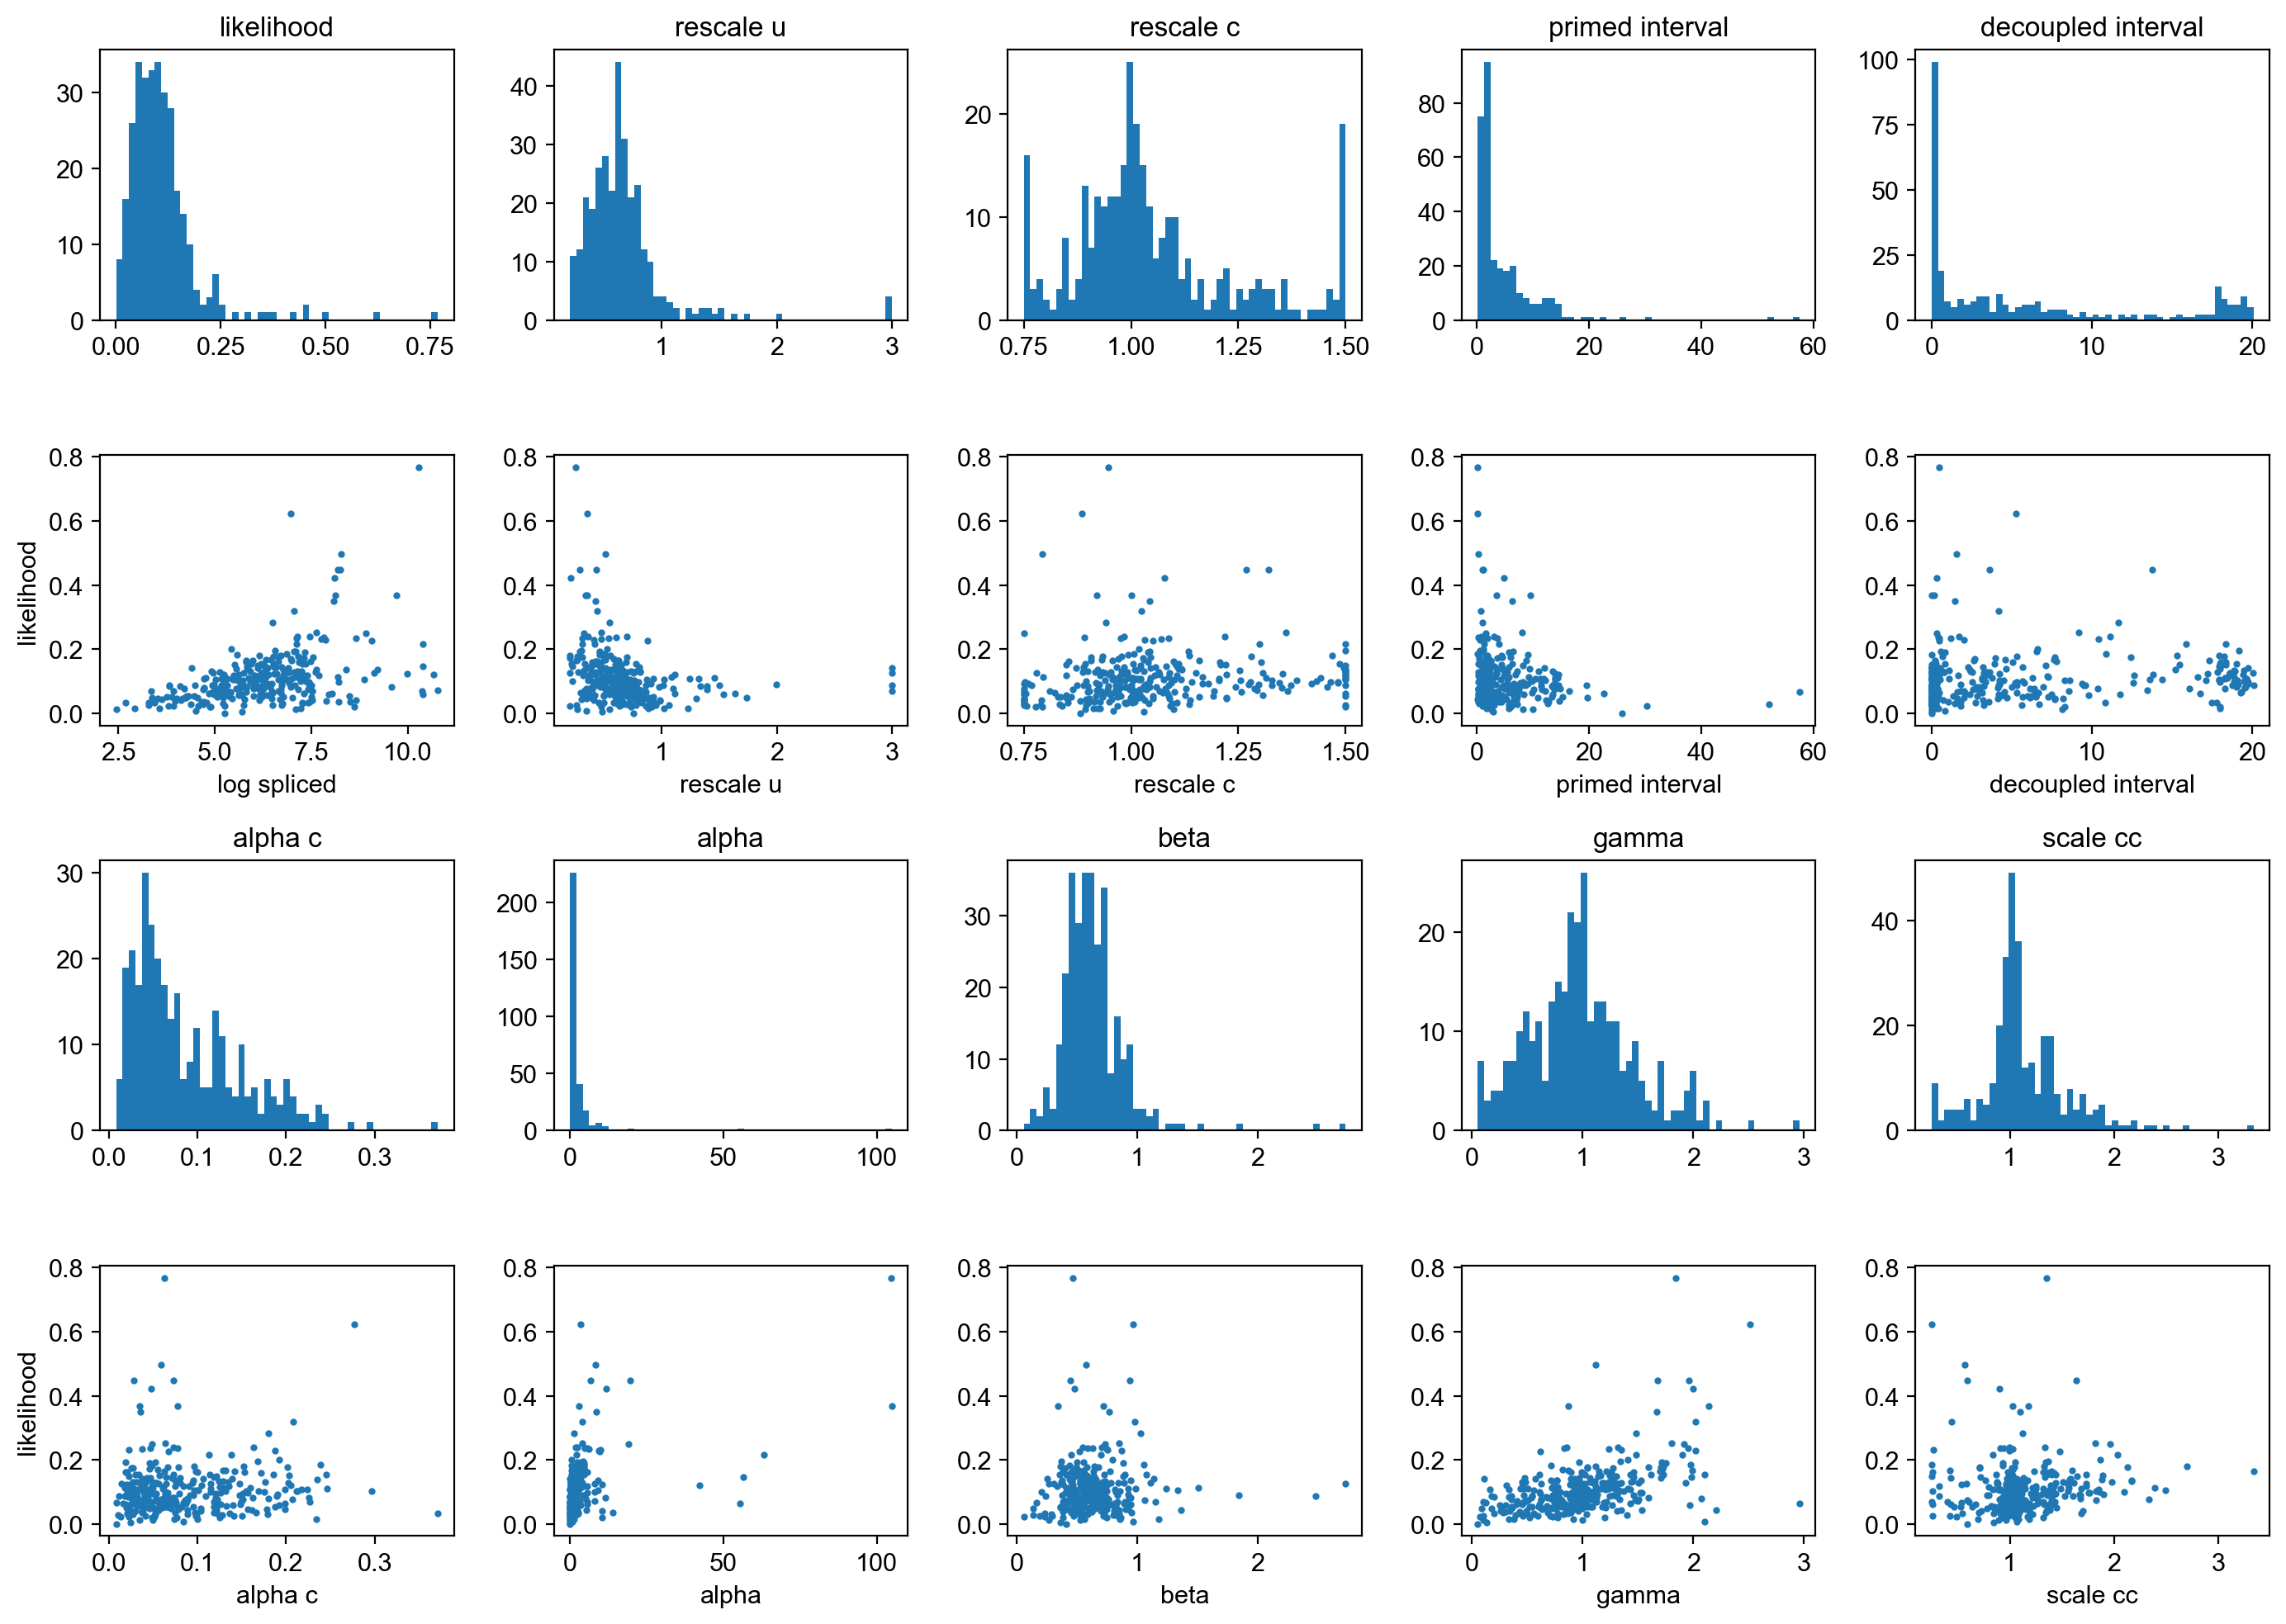

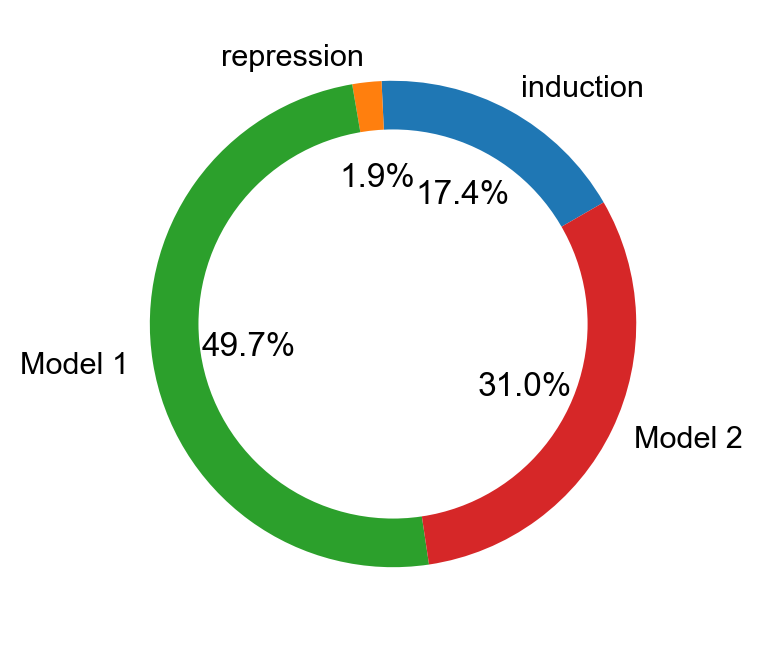

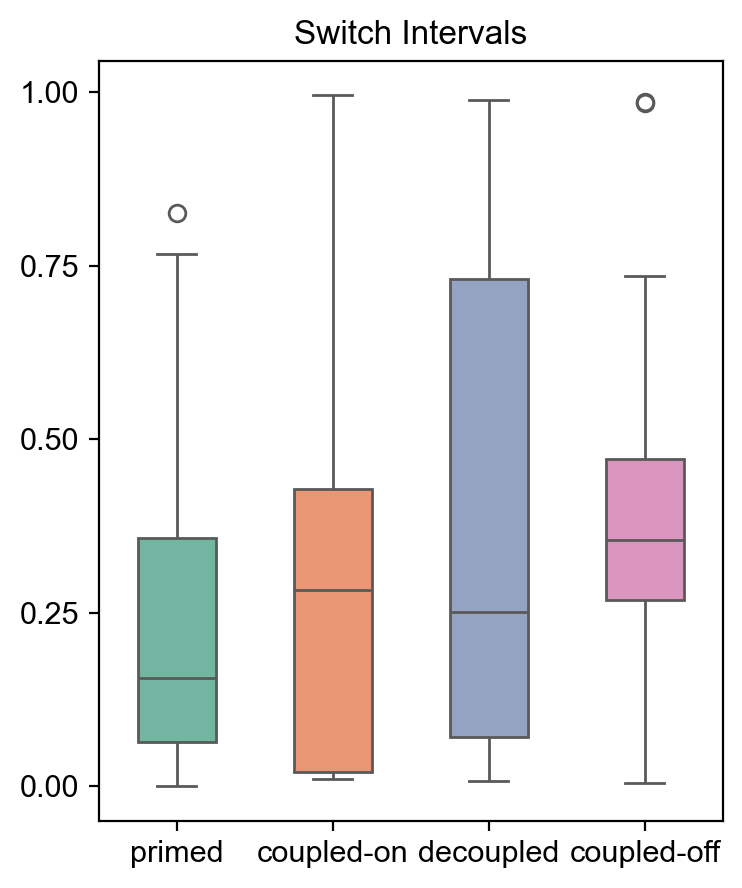

In [26]:
mv.likelihood_plot(adata_result)   # per-gene fit_likelihood vs fit_likelihood_c scatter
mv.pie_summary(adata_result)       # breakdown of fit_model / fit_direction across genes
mv.switch_time_summary(adata_result)

In [ ]:
fit_df = adata_result.var[['fit_likelihood', 'fit_likelihood_c']].dropna()
fit_df['score'] = fit_df.min(axis=1)
ranked_genes = fit_df.sort_values('score', ascending=False).index

for n in [500, 200, 100, 50, 25]:
    sub = adata_result[:, ranked_genes[:n]].copy()  # .copy() — avoid writing to a view
    mv.velocity_graph(sub)
    mv.latent_time(sub)
    mv.velocity_embedding_stream(sub, basis='umap', color='celltype')
    sub.write(f"{output_path}subset_{n}.h5ad")